# SBI812 — Lecture 4
## Decision Trees and Random Forests

### Learning outcomes

By the end of this lecture, a student should be able to:

1. identify the root, decision nodes, branches and leaves of a decision tree;
2. explain why a tree tests midpoints that are not measured values;
3. calculate Gini impurity for a node;
4. calculate the weighted impurity of a proposed split;
5. justify the thresholds selected at successive nodes;
6. follow a tree by hand to predict new observations;
7. fit, display, evaluate and use a decision tree with scikit-learn; and
8. explain how a random forest develops from decision trees and fit one in scikit-learn.

The lecture has two connected parts. First, every important tree decision is reconstructed by hand. Python begins only after the complete tree can be understood and used without software.

## 1. The prediction problem

Sixteen bacterial isolates were exposed to an antibiotic. Each isolate has two measured **features**:

- **efflux expression**: the expression level of an efflux-pump gene;
- **growth rate**: growth measured during the experiment.

The known **target** is the antibiotic response:

- **Sensitive**: the antibiotic inhibits the isolate;
- **Resistant**: the isolate continues to grow.

| Isolate | Efflux expression | Growth rate | Known response |
|---|---:|---:|---|
| S1 | 2.1 | 0.72 | Sensitive |
| S2 | 2.8 | 0.68 | Sensitive |
| S3 | 3.2 | 0.81 | Sensitive |
| S4 | 3.7 | 0.64 | Sensitive |
| S5 | 4.0 | 0.76 | Sensitive |
| S6 | 4.4 | 0.58 | Sensitive |
| S7 | 4.9 | 0.70 | Sensitive |
| S8 | 5.4 | 0.55 | Resistant |
| S9 | 5.9 | 0.48 | Resistant |
| S10 | 6.4 | 0.59 | Resistant |
| S11 | 6.9 | 0.52 | Resistant |
| S12 | 6.2 | 0.71 | Sensitive |
| S13 | 7.2 | 0.78 | Sensitive |
| S14 | 7.9 | 0.69 | Resistant |
| S15 | 8.4 | 0.75 | Resistant |
| S16 | 9.0 | 0.83 | Resistant |

There are 9 Sensitive and 7 Resistant isolates. The aim is to learn questions from these labelled observations and use those questions to predict new isolates.

## 2. The basic idea of a decision tree

A decision tree asks a sequence of questions. Each question has two possible outcomes:

- **Yes**: the condition is true; follow the left branch.
- **No**: the condition is false; follow the right branch.

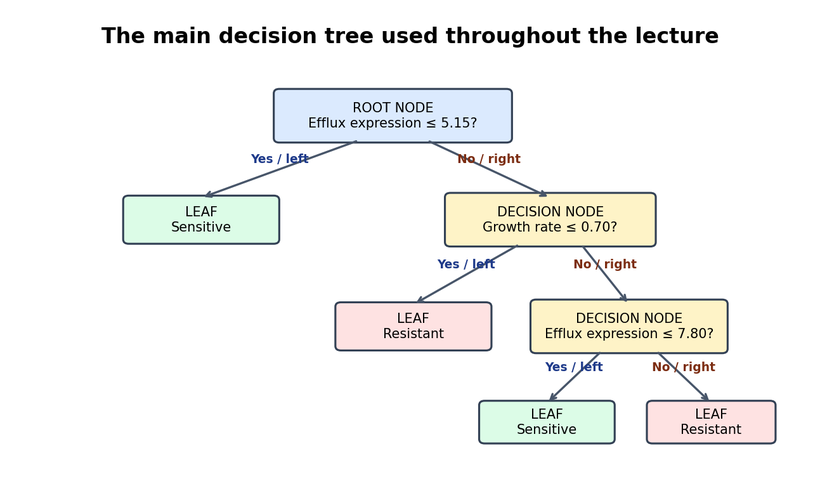

### Parts of the tree

| Part | Meaning |
|---|---|
| Root node | The first question asked of every observation |
| Decision node | A later question reached by only some observations |
| Branch | The path taken after answering Yes or No |
| Leaf | A final prediction; no further question is asked |
| Depth | The number of decisions from the root to a node |

The diagram shows the tree that will be constructed during this lecture. Its thresholds are not guessed. The following sections show where each one comes from.

### How the guided activity will develop this tree

The completed tree above is the destination, not the starting point. The following activity reconstructs it one decision at a time. At each stage, the relevant observations are sorted, a midpoint is justified, Gini impurity is calculated, and the partial tree is redrawn before continuing.


## 3. Begin with the impurity of the root

Before splitting, all 16 isolates occupy one node:

- Sensitive = 9
- Resistant = 7
- Total = 16

Gini impurity measures how mixed a node is:

$$Gini=1-p_{Sensitive}^{2}-p_{Resistant}^{2}$$

Calculate the class proportions:

$$p_{Sensitive}=\frac{9}{16}=0.5625$$

$$p_{Resistant}=\frac{7}{16}=0.4375$$

Therefore:

$$Gini_{root}=1-(0.5625)^2-(0.4375)^2=0.4922$$

For two classes:

| Gini value | Meaning |
|---:|---|
| 0 | The node contains only one class |
| Near 0 | One class strongly dominates |
| 0.5 | The two classes are evenly mixed |

The root value 0.4922 is close to 0.5, so the root is strongly mixed. A useful question should create child nodes with less mixture.

## 4. Sort a feature and generate candidate thresholds

The tree first considers possible dividing positions. Sort the efflux-expression values and keep each response label attached to its value:

The sorted values are displayed in two lines so that every value remains visible. Continue reading from the first line to the second.

**Sorted positions 1–8**

| Efflux expression | 2.1 | 2.8 | 3.2 | 3.7 | 4.0 | 4.4 | **4.9** | **5.4** |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| Response | S | S | S | S | S | S | **S** | **R** |

**Sorted positions 9–16**

| Efflux expression | 5.9 | 6.2 | 6.4 | 6.9 | 7.2 | 7.9 | 8.4 | 9.0 |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| Response | R | S | R | R | S | R | R | R |

The figure below restores the complete sequence on one horizontal number line.

The first seven observations form a continuous Sensitive group. The next observed value, 5.4, is Resistant. This makes the gap between **4.9 and 5.4** a promising dividing position.

A threshold is placed halfway between neighbouring distinct values:

$$\text{midpoint}=\frac{\text{left value}+\text{right value}}{2}$$

For 4.9 and 5.4:

$$\frac{4.9+5.4}{2}=5.15$$

Thus, 5.15 is not a measured value and was not chosen randomly. It is a candidate boundary between two neighbouring measurements.

### Figure: the first sorted feature

Blue points are Sensitive and red points are Resistant. The dashed line lies between 4.9 and 5.4; it is not one of the observations.

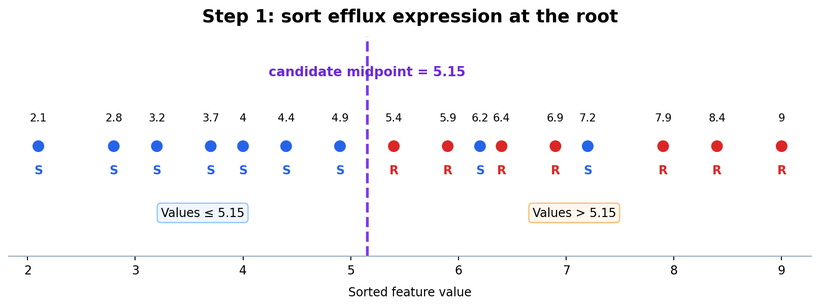


### Candidate midpoint activity

Complete the midpoint calculations before checking the final column.

| Neighbouring values | Calculation | Candidate threshold |
|---|---|---:|
| 2.1 and 2.8 | $(2.1+2.8)/2$ | 2.45 |
| 2.8 and 3.2 | $(2.8+3.2)/2$ | 3.00 |
| 3.2 and 3.7 | $(3.2+3.7)/2$ | 3.45 |
| 3.7 and 4.0 | $(3.7+4.0)/2$ | 3.85 |
| 4.0 and 4.4 | $(4.0+4.4)/2$ | 4.20 |
| 4.4 and 4.9 | $(4.4+4.9)/2$ | 4.65 |
| **4.9 and 5.4** | **$(4.9+5.4)/2$** | **5.15** |
| 5.4 and 5.9 | $(5.4+5.9)/2$ | 5.65 |
| 5.9 and 6.2 | $(5.9+6.2)/2$ | 6.05 |
| 6.2 and 6.4 | $(6.2+6.4)/2$ | 6.30 |
| **6.4 and 6.9** | **$(6.4+6.9)/2$** | **6.65** |
| 6.9 and 7.2 | $(6.9+7.2)/2$ | 7.05 |
| 7.2 and 7.9 | $(7.2+7.9)/2$ | 7.55 |
| 7.9 and 8.4 | $(7.9+8.4)/2$ | 8.15 |
| 8.4 and 9.0 | $(8.4+9.0)/2$ | 8.70 |

These are only **candidates**. The algorithm evaluates candidates from every available feature. It selects the feature and threshold producing the largest decrease in impurity.

## 5. Evaluate the proposed root threshold 5.15

The question is: **Is efflux expression ≤ 5.15?**

| Left child: value ≤ 5.15 | Right child: value > 5.15 |
|---|---|
| S1–S7: 7 Sensitive, 0 Resistant | S8–S16: 2 Sensitive, 7 Resistant |

### Left-child impurity

$$Gini_{left}=1-\left(\frac{7}{7}\right)^2-\left(\frac{0}{7}\right)^2=0$$

### Right-child impurity

$$Gini_{right}=1-\left(\frac{2}{9}\right)^2-\left(\frac{7}{9}\right)^2=0.3457$$

Because the children contain different numbers of observations, use a weighted average:

$$Gini_{split}=\frac{7}{16}(0)+\frac{9}{16}(0.3457)=0.1944$$

The impurity decrease is:

$$0.4922-0.1944=0.2978$$

The left child is pure, while the right child remains mixed. The large impurity decrease makes this a strong split.

### Figure: the tree after the first decision

The pure left child stops. The mixed right child is the only part of the tree that continues to grow.

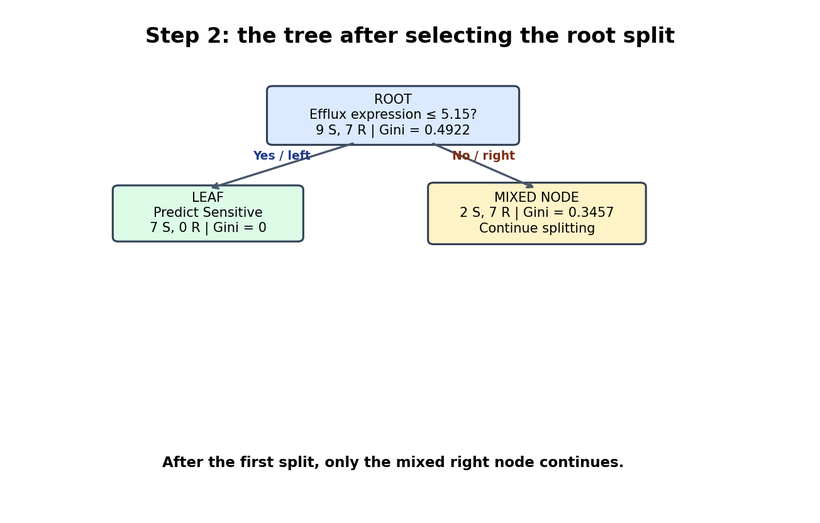


## 6. Compare 5.15 with another candidate

The midpoint between 6.4 and 6.9 is:

$$\frac{6.4+6.9}{2}=6.65$$

Testing **efflux expression ≤ 6.65** gives:

| Child | Sensitive | Resistant | Total | Gini |
|---|---:|---:|---:|---:|
| Left | 8 | 3 | 11 | 0.3967 |
| Right | 1 | 4 | 5 | 0.3200 |

$$Gini_{split}=\frac{11}{16}(0.3967)+\frac{5}{16}(0.3200)=0.3727$$

$$\text{impurity decrease}=0.4922-0.3727=0.1195$$

| Threshold | Weighted impurity | Impurity decrease |
|---:|---:|---:|
| **5.15** | **0.1944** | **0.2978** |
| 6.65 | 0.3727 | 0.1195 |

The tree prefers **5.15** because it leaves less impurity after splitting and therefore produces the larger impurity decrease. The same comparison is made for all candidate thresholds of both features.

## 7. Continue only with the mixed branch

The left child produced by 5.15 contains seven Sensitive isolates and is already pure. It becomes a leaf. The algorithm does not split it again.

Only the nine observations reaching the right child are considered when choosing the next decision:

| Growth rate | 0.48 | 0.52 | 0.55 | 0.59 | **0.69** | **0.71** | 0.75 | 0.78 | 0.83 |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| Response | R | R | R | R | **R** | **S** | R | S | R |

The midpoint between neighbouring values 0.69 and 0.71 is:

$$\frac{0.69+0.71}{2}=0.70$$

The question **growth rate ≤ 0.70?** creates:

| Child | Sensitive | Resistant | Gini |
|---|---:|---:|---:|
| Yes / left | 0 | 5 | 0.0000 |
| No / right | 2 | 2 | 0.5000 |

$$Gini_{split}=\frac{5}{9}(0)+\frac{4}{9}(0.5)=0.2222$$

The parent impurity was 0.3457, so the decrease is:

$$0.3457-0.2222=0.1235$$

The Yes branch is now a pure Resistant leaf. The No branch still contains two Sensitive and two Resistant isolates.

### Figure: sorting only the observations that reached this node

The nine growth-rate values are sorted without returning to the seven observations that already entered the Sensitive leaf.

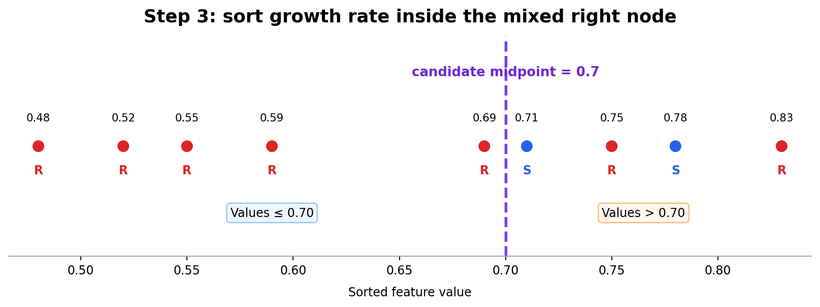

### Figure: the tree after the second decision

The five-observation Resistant child is pure. Only the four-observation mixed child continues.

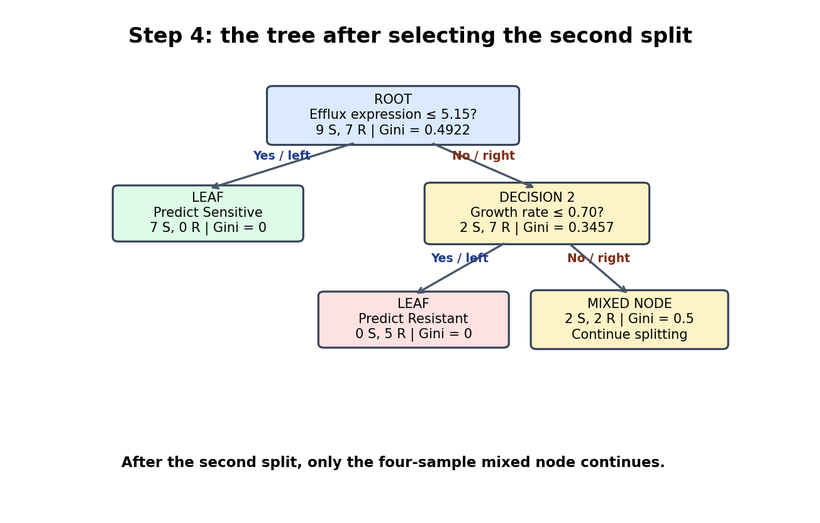


## 8. Select the third decision

Only four observations reach the remaining mixed node because they passed both earlier tests:

- efflux expression > 5.15; and
- growth rate > 0.70.

| Isolate | Efflux expression | Growth rate | Response |
|---|---:|---:|---|
| S12 | 6.2 | 0.71 | Sensitive |
| S13 | 7.2 | 0.78 | Sensitive |
| S15 | 8.4 | 0.75 | Resistant |
| S16 | 9.0 | 0.83 | Resistant |

After sorting efflux expression:

| Efflux expression | 6.2 | **7.2** | **8.4** | 9.0 |
|---|---:|---:|---:|---:|
| Response | S | **S** | **R** | R |

The useful neighbouring values at this node are 7.2 and 8.4:

$$\frac{7.2+8.4}{2}=7.80$$

The question **efflux expression ≤ 7.80?** sends both Sensitive isolates left and both Resistant isolates right. Both child impurities are 0, so this node is completely resolved.

Notice that 7.9 is not used to calculate this midpoint. S14 has growth rate 0.69 and therefore entered the Resistant leaf at the previous decision. It never reaches this node.

### Figure: sorting the four observations at the final mixed node

At this stage, 7.2 and 8.4 are neighbours because the other observations have already followed different branches.

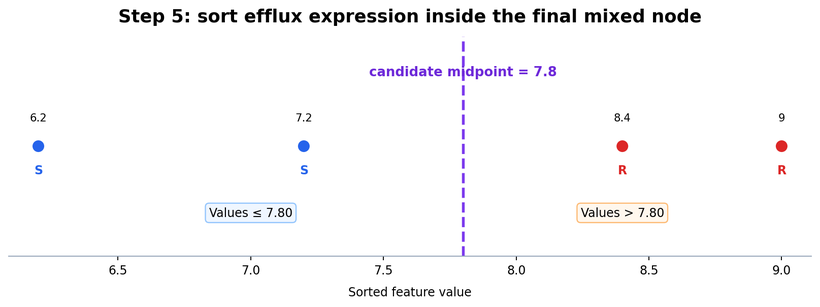


## 9. The completed hand-built tree

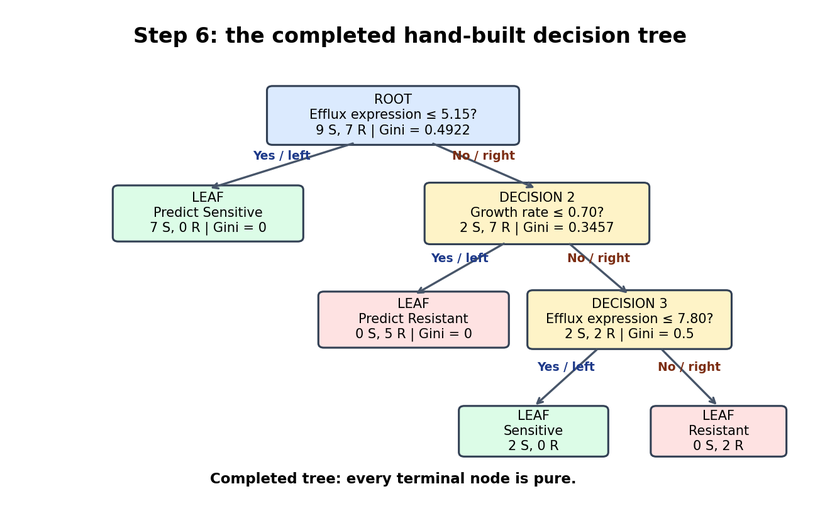

The tree can be written as four rules:

1. If efflux expression ≤ 5.15, predict **Sensitive**.
2. Otherwise, if growth rate ≤ 0.70, predict **Resistant**.
3. Otherwise, if efflux expression ≤ 7.80, predict **Sensitive**.
4. Otherwise, predict **Resistant**.

The figures above should be read as a sequence: the tree grows only where a node remains mixed. It never returns to observations that have already reached a pure leaf.


## 10. Predict new isolates by hand

For each isolate, begin at the root. Ask only the questions reached along its path.

First read the measurements:

| Isolate | Efflux expression | Growth rate |
|---|---:|---:|
| A | 4.6 | 0.80 |
| B | 5.8 | 0.60 |
| C | 6.8 | 0.72 |
| D | 8.1 | 0.74 |
| E | 5.15 | 0.90 |
| F | 7.6 | 0.80 |

Then record the route through the tree:

| Isolate | Q1 | Q2 | Q3 | Prediction |
|---|---|---|---|---|
| A |  | — | — |  |
| B |  |  | — |  |
| C |  |  |  |  |
| D |  |  |  |  |
| E |  | — | — |  |
| F |  |  |  |  |

where:

- **Q1:** efflux expression ≤ 5.15?
- **Q2:** growth rate ≤ 0.70?
- **Q3:** efflux expression ≤ 7.80?

The dash means **the tree stopped before reaching this question**. It does not mean No, and it does not mean that the measurement is missing.

### Checkpoint

| Isolate | Q1 | Q2 | Q3 | Prediction | Path |
|---|---|---|---|---|---|
| A | Yes | — | — | Sensitive | Left from the root |
| B | No | Yes | — | Resistant | Right, then left |
| C | No | No | Yes | Sensitive | Right, right, then left |
| D | No | No | No | Resistant | Right three times |
| E | Yes | — | — | Sensitive | Equality is included by ≤ |
| F | No | No | Yes | Sensitive | Right, right, then left |

“Right, then left” describes branch direction: **No goes right** and **Yes goes left**. It is shorthand for the answers, not a separate calculation.

# Part II — Implementing the model with scikit-learn

The hand calculations have established what the algorithm is doing. Software is now useful because a real dataset may contain hundreds or thousands of observations, many features, and many candidate thresholds.

The next cells use scikit-learn to:

1. store the data;
2. separate features from the target;
3. fit and display the same tree;
4. compare software predictions with the hand predictions; and
5. demonstrate a train/test workflow and a random forest.

## 11. Enter the labelled data

`pandas` stores the observations in a table called a DataFrame. Each list below becomes one column. Values at the same list position belong to the same row.

In [1]:
import pandas as pd

data = pd.DataFrame({
    "sample": ["S1", "S2", "S3", "S4", "S5", "S6", "S7", "S8",
               "S9", "S10", "S11", "S12", "S13", "S14", "S15", "S16"],
    "efflux_expression": [2.1, 2.8, 3.2, 3.7, 4.0, 4.4, 4.9, 5.4,
                          5.9, 6.4, 6.9, 6.2, 7.2, 7.9, 8.4, 9.0],
    "growth_rate": [0.72, 0.68, 0.81, 0.64, 0.76, 0.58, 0.70, 0.55,
                    0.48, 0.59, 0.52, 0.71, 0.78, 0.69, 0.75, 0.83],
    "response": ["Sensitive", "Sensitive", "Sensitive", "Sensitive",
                 "Sensitive", "Sensitive", "Sensitive", "Resistant",
                 "Resistant", "Resistant", "Resistant", "Sensitive",
                 "Sensitive", "Resistant", "Resistant", "Resistant"]
})

data


,sample,efflux_expression,growth_rate,response
0,S1,2.1,0.72,Sensitive
1,S2,2.8,0.68,Sensitive
2,S3,3.2,0.81,Sensitive
3,S4,3.7,0.64,Sensitive
4,S5,4.0,0.76,Sensitive
5,S6,4.4,0.58,Sensitive
6,S7,4.9,0.70,Sensitive
7,S8,5.4,0.55,Resistant
8,S9,5.9,0.48,Resistant
9,S10,6.4,0.59,Resistant


## 12. Separate identifiers, features and target

- `sample` identifies each row but is not a measured predictor.
- `X` contains the two feature columns used to make decisions.
- `y` contains the known response that the model must learn to predict.

Double square brackets keep `X` as a two-dimensional table. Single square brackets select `y` as one column.

In [2]:
sample_ids = data["sample"]
X = data[["efflux_expression", "growth_rate"]]
y = data["response"]

print("Feature-table shape:", X.shape)
print("Number of target labels:", len(y))


Feature-table shape: (16, 2)
Number of target labels: 16


## 13. Fit the complete demonstration tree

This first model uses all 16 rows so that its structure can be compared directly with the hand-built tree.

- `criterion="gini"` requests the impurity measure calculated earlier.
- `max_depth=3` permits at most three decisions along a path.
- `random_state=42` makes operations involving randomness reproducible.
- `fit(X, y)` searches the candidate splits and stores the resulting tree.

Using all rows is appropriate for confirming the hand calculation, but it does **not** provide an independent evaluation. A train/test evaluation follows later.

In [3]:
from sklearn.tree import DecisionTreeClassifier

demonstration_tree = DecisionTreeClassifier(
    criterion="gini",
    max_depth=3,
    random_state=42
)

demonstration_tree.fit(X, y)


,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at 

## 14. Display the fitted tree

`plot_tree()` draws every node. Each box reports:

- the decision rule;
- `gini`, the impurity of observations reaching the node;
- `samples`, the number of training observations at that node;
- `value`, the class counts in the order shown by `classes_`; and
- `class`, the majority class predicted at that node.

The class order must be checked rather than guessed.

Class order: ['Resistant' 'Sensitive']


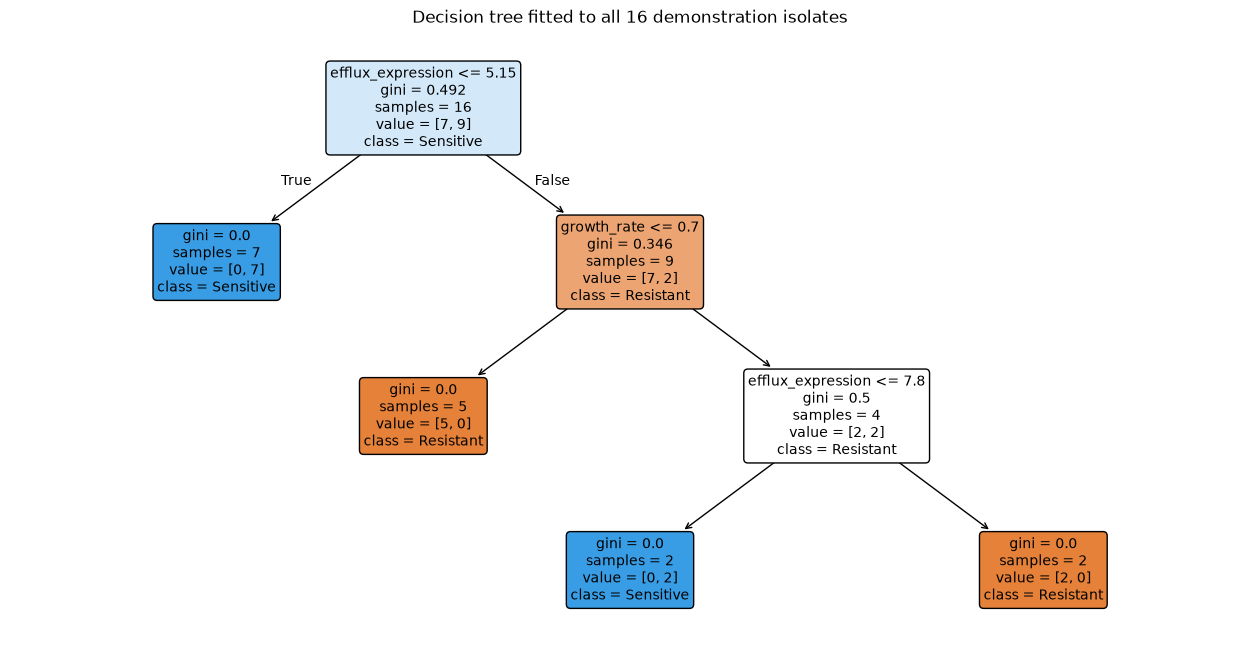

In [4]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

print("Class order:", demonstration_tree.classes_)

plt.figure(figsize=(16, 8))
plot_tree(
    demonstration_tree,
    feature_names=X.columns,
    class_names=demonstration_tree.classes_,
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Decision tree fitted to all 16 demonstration isolates")
plt.show()


## 15. Compare hand predictions with software

The new table uses the same two feature names and the same column order as `X`. `predict()` sends each row through the fitted tree and returns the leaf's class.

In [5]:
new_isolates = pd.DataFrame({
    "efflux_expression": [4.6, 5.8, 6.8, 8.1, 5.15, 7.6],
    "growth_rate": [0.80, 0.60, 0.72, 0.74, 0.90, 0.80]
}, index=["A", "B", "C", "D", "E", "F"])

software_predictions = demonstration_tree.predict(new_isolates)

prediction_comparison = new_isolates.copy()
prediction_comparison["hand_prediction"] = [
    "Sensitive", "Resistant", "Sensitive",
    "Resistant", "Sensitive", "Sensitive"
]
prediction_comparison["software_prediction"] = software_predictions
prediction_comparison


,efflux_expression,growth_rate,hand_prediction,software_prediction
A,4.60,0.80,Sensitive,Sensitive
B,5.80,0.60,Resistant,Resistant
C,6.80,0.72,Sensitive,Sensitive
D,8.10,0.74,Resistant,Resistant
E,5.15,0.90,Sensitive,Sensitive
F,7.60,0.80,Sensitive,Sensitive


The hand and software predictions should agree. Agreement confirms that the tree was followed correctly; it does not prove that the model will always be correct on future biological samples.

## 16. Evaluate a tree on unseen observations

In a real modelling workflow, predictions must be evaluated on observations not used to fit the model.

`train_test_split()` creates:

- a **training set**, used to fit the tree; and
- a **test set**, kept aside until prediction.

Because this teaching dataset contains only 16 observations, the test result will be unstable and should not be treated as a scientific performance estimate. A real study requires substantially more representative observations.

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

evaluation_tree = DecisionTreeClassifier(
    criterion="gini",
    max_depth=3,
    random_state=42
)

evaluation_tree.fit(X_train, y_train)
test_predictions = evaluation_tree.predict(X_test)

print("Training observations:", len(X_train))
print("Test observations:", len(X_test))
print("Test accuracy:", round(accuracy_score(y_test, test_predictions), 3))


Training observations: 12
Test observations: 4
Test accuracy: 1.0


`stratify=y` helps preserve the class proportions in both subsets. `accuracy_score()` calculates the fraction of test predictions that match the known responses.

A confusion matrix shows the types of correct and incorrect predictions. Diagonal cells are correct predictions; off-diagonal cells are errors. Always read the printed axis labels before interpreting the counts.

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    labels=["Sensitive", "Resistant"],
    cmap="Blues"
)
plt.title("Decision-tree predictions on the test set")
plt.show()


## 17. From one tree to a random forest

A single decision tree can change considerably when the training observations change slightly. A deep tree may also memorize the training set, a problem called **overfitting**.

A **random forest** combines many deliberately varied decision trees:

1. each tree receives a random sample of training rows;
2. only a random subset of features is considered at each split; and
3. the trees vote, with the majority class becoming the forest prediction.

The impurity and splitting ideas do not need to be calculated again by hand. They are the same ideas already established for one tree. The forest changes how many varied trees are combined.

## 18. Fit and evaluate a random forest

- `n_estimators=200` creates 200 trees.
- `max_depth=3` restricts each tree's depth.
- `random_state=42` makes the random sampling reproducible.
- The forest is fitted only on the training set and evaluated on the same untouched test set used for the evaluation tree.

In [ ]:
from sklearn.ensemble import RandomForestClassifier

forest_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=3,
    random_state=42
)

forest_model.fit(X_train, y_train)
forest_test_predictions = forest_model.predict(X_test)

forest_accuracy = accuracy_score(y_test, forest_test_predictions)
print("Random-forest test accuracy:", round(forest_accuracy, 3))


The forest score should be interpreted cautiously because only four observations are in this demonstration test set. In a real study, model comparison should use a larger independent test set or carefully designed cross-validation.

## 19. Predict new isolates with the random forest

The same feature table can be passed to the fitted forest. The predicted class is the result of voting across its trees.

In [ ]:
forest_new_predictions = forest_model.predict(new_isolates)

forest_results = new_isolates.copy()
forest_results["forest_prediction"] = forest_new_predictions
forest_results


## 20. Inspect feature importance

A fitted forest reports how much each feature contributed to reducing impurity across its trees. Larger values mean that the feature was used more strongly by this fitted model.

Feature importance does not prove causation, and correlated features can divide importance between themselves.

In [ ]:
importance_table = pd.DataFrame({
    "feature": X.columns,
    "importance": forest_model.feature_importances_
}).sort_values("importance", ascending=False)

importance_table


## 21. Decision tree and random forest compared

| Property | Decision tree | Random forest |
|---|---|---|
| Number of trees | One | Many |
| Prediction | Leaf reached by one path | Majority vote across trees |
| Interpretation | A complete path can be followed | The complete forest is harder to inspect |
| Sensitivity to small data changes | Often higher | Usually lower |
| Overfitting control | Restrict tree complexity | Combine varied restricted trees |
| Feature importance | Available | Available and averaged across trees |

A small tree is useful when transparent rules are required. A random forest is often preferred when predictive stability is more important than tracing one short decision path.

## 22. Complete workflow summary

### Logic understood by hand

1. Count the classes at the current node.
2. Calculate the node's Gini impurity.
3. Sort each feature while keeping labels attached.
4. place candidates midway between neighbouring distinct values.
5. Divide observations into left and right children for each candidate.
6. Calculate each child's Gini impurity.
7. Calculate weighted impurity and impurity decrease.
8. Select the feature and threshold giving the largest decrease.
9. Repeat only inside children that still require splitting.
10. Follow Yes/left and No/right branches to make predictions.

### Practical scikit-learn workflow

1. keep identifiers, feature columns and target labels distinct;
2. divide observations into training and test sets;
3. fit the model using training data only;
4. predict the untouched test observations;
5. evaluate accuracy and the confusion matrix;
6. fit a random forest when a more stable collection of trees is appropriate; and
7. use the final fitted model to predict genuinely new observations.

The hand calculation explains every decision made by one small tree. Scikit-learn makes the same logic usable for larger datasets.

## 23. Practice exercises

### Exercise 1 — Follow the tree

For each observation, write every question reached, its Yes/No answer, and the final prediction:

1. efflux expression 4.2, growth rate 0.82;
2. efflux expression 6.0, growth rate 0.65;
3. efflux expression 7.4, growth rate 0.76;
4. efflux expression 8.6, growth rate 0.68.

### Exercise 2 — Calculate a midpoint

Neighbouring sorted measurements are 10.2 and 11.0. Calculate their midpoint, write the decision rule using ≤, and state the branch taken by a value of 10.7.

### Exercise 3 — Calculate Gini impurity

A node contains 6 Sensitive and 2 Resistant observations. Calculate both proportions and the Gini impurity. State whether the node is pure or mixed.

### Exercise 4 — Compare proposed splits

The parent impurity is 0.46. Split A produces weighted impurity 0.18; Split B produces 0.31. Calculate both impurity decreases and select the better split.

### Exercise 5 — Use scikit-learn

Using the lecture data, fit a decision tree with `max_depth=2`. Display it and compare its structure with the depth-three demonstration tree.

### Exercise 6 — Random forest

Fit a random forest containing 100 trees. Predict the six rows in `new_isolates` and display its feature-importance table.